# HSA_Cam_B_013.py
This file uses the LHHW_Model of kinetics and KLD to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_004.py is the model. This uses homoscedastic noise and exponential priors.

Analysis from the related python script.

### Plan:
* load the data
* generate the plots
* check the reduction in KLD
* check the reduction in HDI
* check the parameter uncertainties
* check the exploration pattern

### Results:
* Leave out the first 4 experiments completely

In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_C_001_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
)
from HSA_Mo_B_004_pyro import kinetics_model

In [3]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [4]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(T, p, c2h, f, c2i, noise_std=0.0)

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    return fig, ax

In [5]:
data_path = Path(f"data/C_001/")
trace_file = data_path / "trace.nc"

In [6]:
idata = az.from_netcdf(trace_file)

In [10]:
proposals = torch.tensor(
    [
        [525, 2.0, 0.5, 10, 0.5],
        [550, 2.0, 0.5, 10, 0.5],
        [575, 2.0, 0.5, 10, 0.5],
        [525, 15.0, 0.5, 10, 0.5],
        [550, 15.0, 0.5, 10, 0.5],
        [575, 15.0, 0.5, 10, 0.5],
        [525, 10.0, 2.0, 10, 0.5],
        [550, 10.0, 2.0, 10, 0.5],
        [575, 10.0, 2.0, 10, 0.5],
    ]
)

# Extract experimental conditions
T = proposals[:, 0:1]
p = proposals[:, 1:2]
c2h = proposals[:, 2:3]
f = proposals[:, 3:4]
c2i = proposals[:, 4:5]

# Conduct experiments (generate synthetic observations)
print(f"Conducting {proposals.shape[0]} experiments...")
T, p_i, r_obs = generate_synthetic_data(T, p, c2h, f, c2i, seed=42)

Conducting 9 experiments...


### Display the results:

[None]

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\IPython\core\events.py:82: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



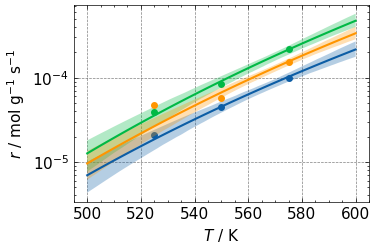

In [34]:
import ICIW_Plots
plt.style.use("ICIWstyle")
%config InlineBackend.print_figure_kwargs = {'bbox_inches':None}

fig = ICIW_Plots.figure(layout="double_column")
ax = ICIW_Plots.make_rect_ax(
    fig,
    ax_width=7.5 * ICIW_Plots.cm2inch,
    ax_height=5.0 * ICIW_Plots.cm2inch,
    xlabel="$T$ / K",
    ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
)
T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)
test_pred = evaluate_conditions(
    proposals[0].numpy(),
    idata,
)
true_pred = evaluate_true_model(proposals[0].numpy())
plot_predictions(
    fig,
    ax,
    proposals[0].numpy(),
    test_pred,
    true_pred,
    T_range=T.squeeze().cpu().numpy(),
)
ax.scatter(
    proposals[0:3, 0],
    r_obs[0:3],
    c=f"C{0}"
)
test_pred = evaluate_conditions(
    proposals[3].numpy(),
    idata,
)
true_pred = evaluate_true_model(proposals[3].numpy())
plot_predictions(
    fig,
    ax,
    proposals[3].numpy(),
    test_pred,
    true_pred,
    T_range=T.squeeze().cpu().numpy(),
)
ax.scatter(
    proposals[3:6, 0],
    r_obs[3:6],
    c=f"C{1}"
)
test_pred = evaluate_conditions(
    proposals[6].numpy(),
    idata,
)
true_pred = evaluate_true_model(proposals[6].numpy())
plot_predictions(
    fig,
    ax,
    proposals[6].numpy(),
    test_pred,
    true_pred,
    T_range=T.squeeze().cpu().numpy(),
)
ax.scatter(
    proposals[6:9, 0],
    r_obs[6:9],
    c=f"C{2}"
)
ax.set(yscale="log")

[(8e-05, 0.001),
 Text(0.5, 0, '$k_0$'),
 (30000.0, 130000.0),
 Text(0, 0.5, '$E_A$')]

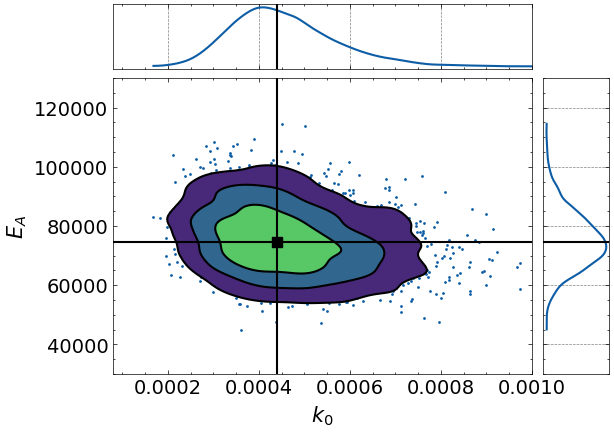

In [23]:
axs = az.plot_pair(
    idata,
    var_names=["k0", "Ea_k"],
    kind=["scatter", "kde"],
    point_estimate="median",
    marginals=True,
).flatten()
axs[2].set(
    xlim=(8e-5, 1e-3),
    xlabel="$k_0$",
    ylim=(30e3, 130e3),
    ylabel="$E_A$",
)